In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [53]:
# ignore the warning that appears while executing the code or cell
import warnings
warnings.filterwarnings('ignore') 

In [54]:
# Load the data
data=pd.read_csv('advertising.csv')

In [55]:
# showing first five rows of the data
data.head() 

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,City,Male,Country,Timestamp,Clicked on Ad
0,68.95,35,61833.90,256.09,Cloned 5thgeneration orchestration,Wrightburgh,0,Tunisia,2016-03-27 00:53:11,0
1,80.23,31,68441.85,193.77,Monitored national standardization,West Jodi,1,Nauru,2016-04-04 01:39:02,0
2,69.47,26,59785.94,236.50,Organic bottom-line service-desk,Davidton,0,San Marino,2016-03-13 20:35:42,0
3,74.15,29,54806.18,245.89,Triple-buffered reciprocal time-frame,West Terrifurt,1,Italy,2016-01-10 02:31:19,0
4,68.37,35,73889.99,225.58,Robust logistical utilization,South Manuel,0,Iceland,2016-06-03 03:36:18,0


In [56]:
#checking number or rows and columns in the data
data.shape

(1000, 10)

In [57]:
# getting only numeric data
adv=data._get_numeric_data()
adv.head()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Male,Clicked on Ad
0,68.95,35,61833.90,256.09,0,0
1,80.23,31,68441.85,193.77,1,0
2,69.47,26,59785.94,236.50,0,0
3,74.15,29,54806.18,245.89,1,0
4,68.37,35,73889.99,225.58,0,0


In [58]:
# Renaming the column names
adv.rename(columns={
    'Daily Time Spent on Site': 'Time_Spent',
    'Area Income': 'Area_Income',
    'Daily Internet Usage':'Internet_Usage',
    'Clicked on Ad': 'Clicked'
    
},inplace=True)
adv.columns

Index(['Time_Spent', 'Age', 'Area_Income', 'Internet_Usage', 'Male',
       'Clicked'],
      dtype='object')

In [59]:
# dividing the data into x and y
x=adv.drop(['Clicked'],axis=1)
x.head()

,Time_Spent,Age,Area_Income,Internet_Usage,Male
0,68.95,35,61833.90,256.09,0
1,80.23,31,68441.85,193.77,1
2,69.47,26,59785.94,236.50,0
3,74.15,29,54806.18,245.89,1
4,68.37,35,73889.99,225.58,0


In [60]:
y=adv[['Clicked']]
y.head()

,Clicked
0,0
1,0
2,0
3,0
4,0


#### Data Partition into train and test data:

In [61]:
### Split the data into train and test data:
from sklearn.model_selection import train_test_split

In [62]:
# data is divided as 70% train and 30% test data
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2, random_state=42) 

In [63]:
# rows and columns of train and test data
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((800, 5), (200, 5), (800, 1), (200, 1))

#### Build the model

In [64]:
from sklearn.linear_model import LogisticRegression

In [65]:
#create the model
model=LogisticRegression(max_iter=200)

In [66]:
#fitting the model
model.fit(x_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,200
,multi_class,'deprecated'


#### Model Evaluation:

In [111]:
from sklearn.metrics import confusion_matrix, classification_report, precision_score,recall_score, f1_score, accuracy_score
from sklearn.metrics import roc_curve, roc_auc_score

In [112]:
#defining the function for AUC-ROC curve that will be used or reused below in the code during model evaluation
def plot_roc(y,y_predict):
    fpr,tpr,thresh=roc_curve(y,y_predict)
    auc=roc_auc_score(y,y_predict)
    print(f'AUC:{auc}')

    plt.figure(figsize=(3,3))
    plt.title('AUC-ROC Curve',fontsize=12)
    plt.xlabel('False Positive Rate(FPR)')
    plt.ylabel('True Positive Rate(TPR)')

    plt.plot(fpr,tpr)
    plt.plot([0,1],[0,1],'o--')
    plt.show()

##### 1. Based on training data:

In [120]:
# train the model on training data
y_train_predict=model.predict(x_train)

In [121]:
cm_train=confusion_matrix(y_train,y_train_predict)
cm_train

array([[402,   9],
       [ 12, 377]])

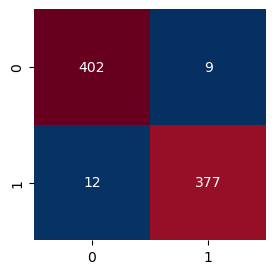

In [122]:
#Representing confusion matrix as a heatmap
plt.figure(figsize=(3,3))
sns.heatmap(cm_train,annot=True,fmt='d',cbar=False,cmap='RdBu_r')
plt.show()

##### Looking at the training_confusion matrix, we can derive that 21 out of 800 values are predicted wrongly or 779 out of 800 values are predicted correctly. The values along the diagonal (left-to-right) should be the maximum number.

AUC:0.9736269303660895


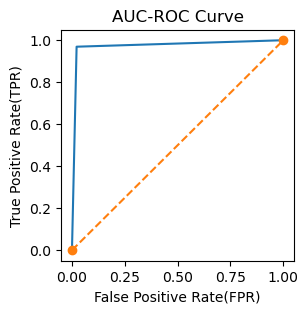

In [139]:
#plotting the auc-roc curve for training data
plot_roc(y_train,y_train_predict)

##### **Conclusion:** The training AUC-ROC curve shows that the logistic regression model separates the two classes very well. The curve rises steeply to the top-left corner, reaching a true positive rate (recall) of about 97% at a false positive rate of only about 2%. This means the model correctly identifies nearly all positive cases while rarely labeling a negative case as positive. The curve sits far above the dashed diagonal line, which represents random guessing (AUC = 0.5), so the model performs much better.

In [133]:
print(classification_report(y_train,y_train_predict))

              precision    recall  f1-score   support

           0       0.97      0.98      0.97       411
           1       0.98      0.97      0.97       389

    accuracy                           0.97       800
   macro avg       0.97      0.97      0.97       800
weighted avg       0.97      0.97      0.97       800



##### 1. Based on testing data:

In [134]:
y_test_predict=model.predict(x_test)

In [135]:
cm_test=confusion_matrix(y_test,y_test_predict)
cm_test

array([[ 83,   6],
       [  5, 106]])

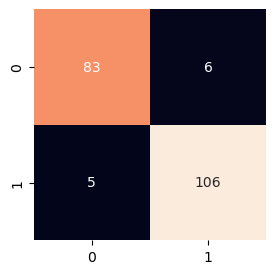

In [136]:
#Representing confusion matrix as a heatmap
plt.figure(figsize=(3,3))
sns.heatmap(cm_test,annot=True,fmt='d',cbar=False)
plt.show()

##### Looking at the test_confusion matrix, we can derive that 11 out of 200 values are predicted wrongly or 189 out of 200 values are predicted correctly. The values along the diagonal (left-to-right) should be the maximum number.

AUC:0.9437696123089382


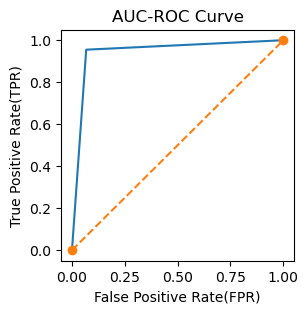

In [140]:
#plotting the auc-roc curve for test data
plot_roc(y_test,y_test_predict)

##### **Conclusion:** The test AUC-ROC curve shows that the logistic regression model separates the two classes very well. The AUC is about 0.944, which is in the excellent range (above 0.9). The curve rises steeply toward the top-left corner, reaching a true positive rate (recall) of about 95% at a false positive rate of only about 6 to 7%. This means the model correctly identifies most positive cases while rarely labeling a negative case as positive. The curve sits well above the dashed diagonal line, which represents random guessing (AUC = 0.5), so the model performs far better than chance. This agrees with the test accuracy of about 94% and supports the conclusion that the model is a good fit and generalizes well to unseen data.

In [141]:
print(classification_report(y_test,y_test_predict))

              precision    recall  f1-score   support

           0       0.94      0.93      0.94        89
           1       0.95      0.95      0.95       111

    accuracy                           0.94       200
   macro avg       0.94      0.94      0.94       200
weighted avg       0.94      0.94      0.94       200



##### **Overall Conclusion:** The logistic regression model fits this advertising dataset well. It achieves an accuracy of about 97% on the training data and about 94% on the test data, so both are above 90%. The two scores are close, with a gap of only about 3 percentage points. This suggests the model has learned the underlying patterns in the data and has not simply memorized the training records, so overfitting is not a major concern. The classification report shows that the two classes are fairly balanced: the training data has 411 records of class 0 and 389 of class 1, and the test data has 89 of class 0 and 111 of class 1. Because neither class dominates, accuracy is a reliable metric for judging this model’s performance.